In [ ]:
import pandas as pd

# Specify the path to your Excel file
excel_file_path = '/content/HH Data - Typical.xlsx'  # Replace with your actual file path

# Read the Excel file into a pandas DataFrame, skipping the first row and the last 2 rows
df = pd.read_excel(excel_file_path, skiprows=2, skipfooter=2, header=0)

# Display the first and last 5 rows of the DataFrame
display(df.head())
display(df.tail())

,Date,00:30:00,01:00:00,01:30:00,02:00:00,02:30:00,03:00:00,03:30:00,04:00:00,04:30:00,...,19:30:00,20:00:00,20:30:00,21:00:00,21:30:00,22:00:00,22:30:00,23:00:00,23:30:00,24:00
0,10125,48,47,48,48,47,49,47,48,48,...,47,50,47,46,45,47,51,51,49,49
1,20125,50,49,52,49,50,51,49,52,48,...,1604,1522,1573,1611,1516,1396,1468,1525,1611,1614
2,30125,1583,1563,1596,1558,1564,1488,1525,1340,1448,...,1531,1490,1342,1471,1474,1554,1560,1470,1577,1553
3,40125,1552,1534,1502,1492,1440,1488,1466,1530,1444,...,51,52,49,47,48,46,47,49,46,48
4,50125,47,48,48,45,47,47,43,46,46,...,45,44,45,47,45,47,46,45,48,45


,Date,00:30:00,01:00:00,01:30:00,02:00:00,02:30:00,03:00:00,03:30:00,04:00:00,04:30:00,...,19:30:00,20:00:00,20:30:00,21:00:00,21:30:00,22:00:00,22:30:00,23:00:00,23:30:00,24:00
360,271225,38,39,38,39,38,37,40,38,38,...,41,41,40,43,40,40,41,40,41,40
361,281225,39,41,40,40,40,39,39,40,38,...,37,39,39,39,39,39,38,41,38,38
362,291225,40,38,39,40,37,39,39,37,39,...,1564,1603,1453,1613,1578,1490,1375,1527,1336,1471
363,301225,1509,1504,1551,1519,1502,1523,1307,1468,1490,...,1548,1634,1641,1559,1412,1211,1402,1560,1521,1625
364,311225,1587,1378,1309,1314,1425,1202,902,707,190,...,41,40,40,40,39,41,39,40,41,40


In [ ]:
df.drop('Date', axis=1, inplace=True)
display(df.head())

,00:30:00,01:00:00,01:30:00,02:00:00,02:30:00,03:00:00,03:30:00,04:00:00,04:30:00,05:00:00,...,19:30:00,20:00:00,20:30:00,21:00:00,21:30:00,22:00:00,22:30:00,23:00:00,23:30:00,24:00
0,48,47,48,48,47,49,47,48,48,47,...,47,50,47,46,45,47,51,51,49,49
1,50,49,52,49,50,51,49,52,48,49,...,1604,1522,1573,1611,1516,1396,1468,1525,1611,1614
2,1583,1563,1596,1558,1564,1488,1525,1340,1448,1508,...,1531,1490,1342,1471,1474,1554,1560,1470,1577,1553
3,1552,1534,1502,1492,1440,1488,1466,1530,1444,1335,...,51,52,49,47,48,46,47,49,46,48
4,47,48,48,45,47,47,43,46,46,47,...,45,44,45,47,45,47,46,45,48,45


In [ ]:
import numpy as np

vec = df.to_numpy().flatten()
vec

array([48, 47, 48, ..., 40, 41, 40])

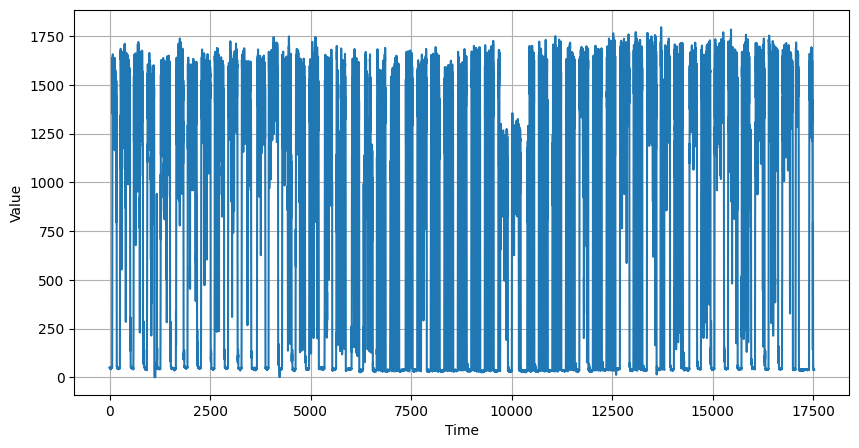

In [ ]:
import matplotlib.pyplot as plt

# 'vector' is your flattened array from the previous step
plt.figure(figsize=(10, 5))
plt.plot(vec)

# Adding labels for clarity
plt.title("Obs data 2025")
plt.xlabel("Time")
plt.ylabel("Meter")
plt.grid(True)
plt.show()

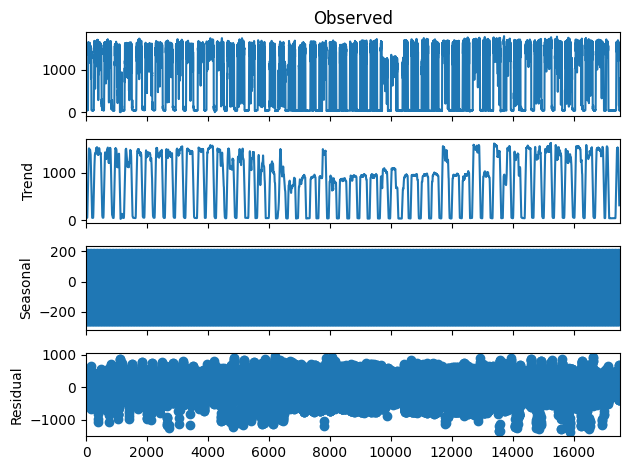

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

# Assuming 'vector' is your flattened data from the previous steps
# period=24 represents the daily cycle (24 hours)
analysis = seasonal_decompose(vec, model='additive', period=48)

# Recreates the 4-panel plot (Observed, Trend, Seasonal, Residual)
analysis.plot()
plt.show()

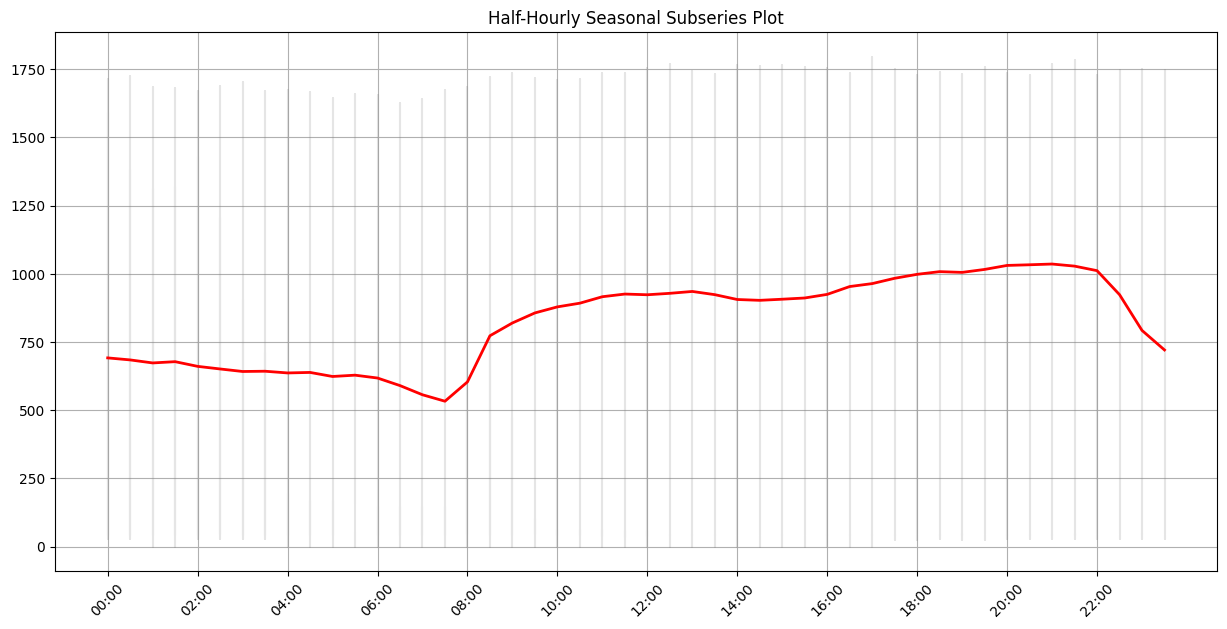

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Create the index with a 30-minute frequency
time_index = pd.date_range(start="2025-01-01", periods=len(vec), freq="30min")
series = pd.Series(vec, index=time_index)

# Plotting the subseries (grouping by time of day)
fig, ax = plt.subplots(figsize=(15, 7))

# Iterate through groups and plot each subseries using time-of-day strings for the x-axis
for time_of_day, group in series.groupby(series.index.time):
    ax.plot(group.index.strftime('%H:%M'), group.values, alpha=0.2, color='gray')

# Optional: Add the mean line for each half-hour (similar to R's monthplot lines)
mean_series = series.groupby(series.index.time).mean()
mean_series.index = mean_series.index.map(lambda t: t.strftime('%H:%M'))
ax.plot(mean_series.index, mean_series.values, color='red', linewidth=2)

plt.title("Half-Hourly Seasonal Subseries Plot")
plt.xticks(rotation=45)

# Set x-axis ticks to display unique time labels, avoiding clutter
unique_times_str = series.index.strftime('%H:%M').unique().sort_values()
ax.set_xticks(unique_times_str[::4]) # Display every 4th label to avoid clutter
ax.set_xticklabels(unique_times_str[::4])

plt.grid(True)
plt.show()

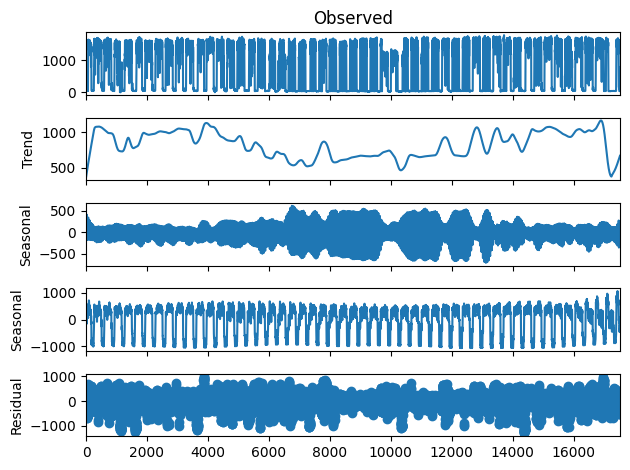

In [ ]:
from statsmodels.tsa.seasonal import MSTL
import matplotlib.pyplot as plt

# Define the periods: 48 (Daily) and 336 (Weekly)
mstl = MSTL(vec, periods=(48, 336))
res = mstl.fit()

# This will plot: Observed, Trend, Seasonal_48, Seasonal_336, and Resid
res.plot()
plt.tight_layout()
plt.show()

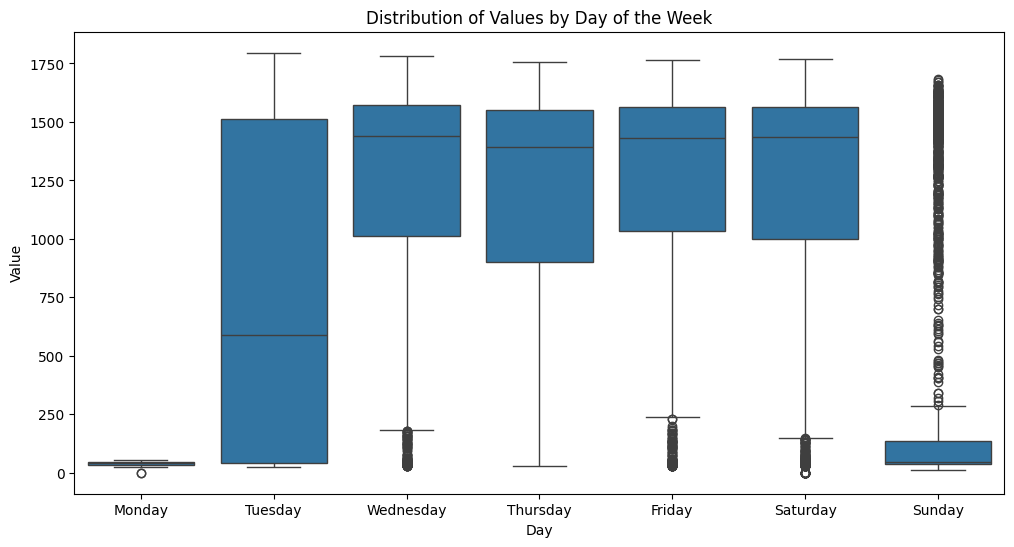

In [ ]:
import seaborn as sns
import pandas as pd

# Create a DataFrame with Time features
df_weekly = pd.DataFrame({'Value': vec}, index=time_index)
df_weekly['Day'] = df_weekly.index.day_name()
df_weekly['Hour'] = df_weekly.index.hour

# Plotting the Weekly distribution
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_weekly, x='Day', y='Value',
            order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.title("Distribution of Values by Day of the Week")
plt.show()

optimization problem

In [1]:
import pandas as pd

# Define the file path
file_path = '/content/Galetech BTM Inputs.xlsx'

demand = pd.read_excel(file_path, sheet_name='Sample Weekly energy demand', skiprows=7, usecols="G:J")
demand.rename(columns={'Unnamed: 6': 'Day', 'Unnamed: 7': 'Hour', 'kW.2': 'Energy (KW)', 'kW.3': 'Gas (KW)'}, inplace=True)

display(demand.head())

,Day,Hour,Energy (KW),Gas (KW)
0,Monday,00:00:00,1.0,NaN
1,Monday,01:00:00,1.0,NaN
2,Monday,02:00:00,1.0,NaN
3,Monday,03:00:00,1.0,NaN
4,Monday,04:00:00,2.9,NaN


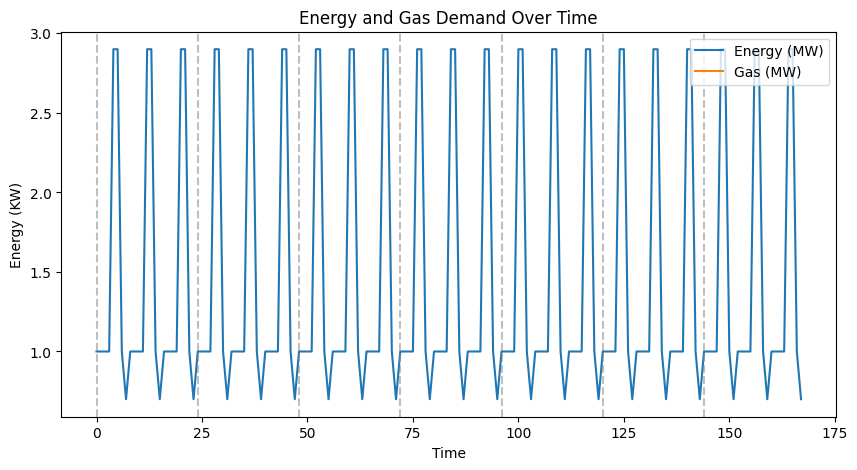

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(demand['Energy (KW)'], label='Energy (MW)')
plt.plot(demand['Gas (KW)'], label='Gas (MW)')
for x in range(0, demand.shape[0], 24):
    plt.axvline(x=x, color='grey', linestyle='--', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Energy (KW)')
plt.title('Energy and Gas Demand Over Time')
plt.legend(loc='upper right')
plt.show()

In [3]:
wind_power = pd.read_excel(file_path, sheet_name='Turbine Type Details', skiprows=2, skipfooter=4, usecols="B:H")
wind_power.rename(columns={'Power kW': 'EWT 500kW', 'Power kW.1': 'E82 2.3MW', 'Power kW.2': 'V90 3MW', 'Power kW.3': 'E138 4.26MW', 'Power kW.4': 'EWT 1MW', 'Power kW.5': 'E115 4.2MW'}, inplace=True)

display(wind_power.tail())
wind_power = wind_power.to_numpy()

,Wind Speed,EWT 500kW,E82 2.3MW,V90 3MW,E138 4.26MW,EWT 1MW,E115 4.2MW
21,21,500,2350,3000,4260,1000,4200
22,22,500,2350,3000,4260,1000,4200
23,23,500,2350,3000,4260,1000,4200
24,24,500,2350,3000,4260,1000,4200
25,25,500,2350,3000,4260,1000,4200


In [4]:
weather_mean = pd.read_csv('/content/cavan_weather_week.csv')
display(weather_mean.head())

,Day,Hour,Wind Speed (m/s),Solar Radiation (W/m2)
0,Monday,00:00,7.2,0
1,Monday,01:00,7.5,0
2,Monday,02:00,7.8,0
3,Monday,03:00,7.6,0
4,Monday,04:00,7.4,0


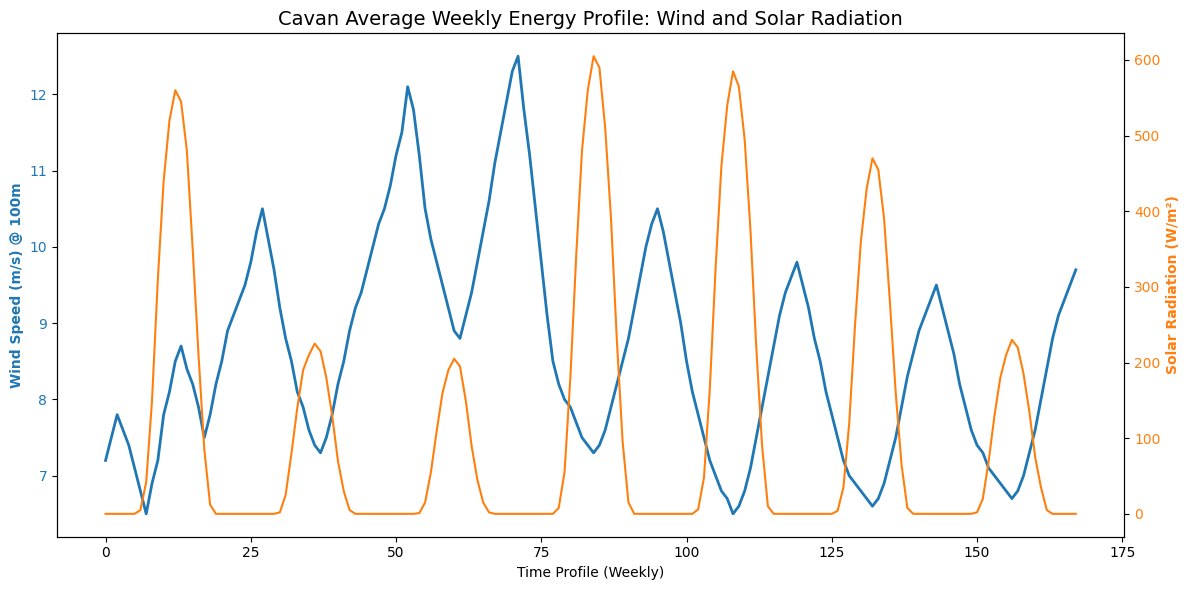

In [5]:
# Create the Time label (Day + Hour) for the X-axis
weather_mean['Time'] = weather_mean['Day'] + " " + weather_mean['Hour']

# 2. Create the Plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# --- Plot Wind Speed on the LEFT Axis ---
color_wind = 'tab:blue'
ax1.set_xlabel('Time Profile (Weekly)')
ax1.set_ylabel('Wind Speed (m/s) @ 100m', color=color_wind, fontweight='bold')
ax1.plot(weather_mean['Wind Speed (m/s)'], color=color_wind, label='Wind Speed', linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_wind)

# --- Create the SECOND axis for Solar ---
ax2 = ax1.twinx()

# --- Plot Solar Radiation on the RIGHT Axis ---
color_solar = 'tab:orange'
ax2.set_ylabel('Solar Radiation (W/m²)', color=color_solar, fontweight='bold')
ax2.plot(weather_mean['Solar Radiation (W/m2)'], color=color_solar, label='Solar Radiation')
ax2.tick_params(axis='y', labelcolor=color_solar)

# 3. Aesthetics
plt.title('Cavan Average Weekly Energy Profile: Wind and Solar Radiation', fontsize=14)
fig.tight_layout()

# Rotate x-axis labels to avoid overlap
plt.xticks(rotation=45)
plt.show()

In [19]:
def out_flow(t, # payback period (years)
             energy_deficit, # max(achieved, demand) - achieved (orange area) (MW)
             n_sp, # number of solar panels (in MW)
             n_w1, n_w2, n_w3, n_w4, n_w5, n_w6, # number of turbines per type
             n_b = 1, # number of batteries
             ):

  # capex calculation
  installation_cost = n_sp * c_install_sp + n_w1 * c_install_w1 + n_w2 * c_install_w2 + n_w3 * c_install_w3 + n_w4 * c_install_w4 + n_w5 * c_install_w5 + n_w6 * c_install_w6 + n_b * c_install_b
  civil_work_cost = n_sp * c_civil_work_sp + (n_w1 + n_w2 + n_w3 + n_w4 + n_w5 + n_w6) * c_civil_work_w + n_b * c_civil_work_b
  electrical_work_cost = (n_sp + n_w1 + n_w2 + n_w3 + n_w4 + n_w5 + n_w6 + n_b) * c_electrical_work
  capex = (installation_cost + civil_work_cost + electrical_work_cost) * (1 + perc_proj_mngt)

  #opex calculation
  electricity_cost = energy_deficit * c_electricity_curr * t
  gas_cost = np.sum(gas_demand) * 52 * c_gas_curr * t
  insurance_cost = capex * perc_insurance * t
  maintenance_cost = capex * perc_maintenance * t
  land_cost = c_land * t
  co2_cost = (np.sum(gas_demand) * 52 * t * gas_MW_tonnes) * c_co2
  opex = electricity_cost + gas_cost + insurance_cost + maintenance_cost + land_cost + co2_cost

  return capex + opex

In [20]:
def in_flow(t, # payback period (years)
            energy_to_grid, # achieved - min(achieved, demand) (pink + blue area) (MW)
            ):
  return energy_to_grid * c_electricity_client * t

In [21]:
#next: need to determine how much battery charge to keep in the reserve to use over next 24 hours
#soc = state of charge at battery at time t (as %)
#reserve soc = percentage of battery capacity to keep in reserve for future use

def calc_reserve_soc_from_excess(forecast_excess, battery_capacity, high_excess_threshold, low_excess_threshold):

    if forecast_excess >= high_excess_threshold:
        reserve_soc = 0.10 * battery_capacity  # keep only 10% battery in reserve if we have a lot of excess

    elif forecast_excess <= low_excess_threshold:
        reserve_soc = 0.80 * battery_capacity  # keep 80% battery in reserve if we have very little excess / shortage expected

    else:
        reserve_soc = 0.40 * battery_capacity  # keep 40% battery in reserve if we have moderate excess

    return reserve_soc

In [22]:
#Battery dispatch function to determine whether to discharge battery at current time t
#battery capacity- max battery capacity in MWh
#max charge power - max power battery can charge in one hour in MW
#max discharge power- max power battery can discharge in one hour in MW
#charge efficiency - percentage power lost to heat when charging battery 0.95 (5%) loss
#discharge efficiency- percentage power lost to heat when discharging battery 0.95
#export limit- max power battery can export to grid in one hour in MW - 5MW
#initial SOC - initial state of charge of battery at time t in MWh
#demand_t demand at time t in MW

def battery_dispatch(
    achieved,
    demand,
    battery_capacity,
    max_charge_power,
    max_discharge_power,
    charge_efficiency=0.95,
    discharge_efficiency=0.95,
    export_limit=5,
    initial_soc=0.0,
    high_excess_threshold=5,
    low_excess_threshold=2,
    horizon=24
):

    n = len(demand) - horizon
    soc = initial_soc
    results = []

    for t in range(n):

        #current hour renewable generation and demand
        renewable_generation = achieved[t]
        demand_t = demand[t]
        excess = renewable_generation - demand_t

        #forecast future renewable generation and demand
        forecasted_generation = achieved[t:t+horizon]
        forecasted_demand = demand[t:t+horizon]

        #calculate forecasted excess for next 24 hours
        #positive excess = more renewable generation than demand
        #negative excess = more demand than renewable generation
        forecasted_excess = forecasted_generation.sum() - forecasted_demand.sum()

        #determine how much battery charge to keep in reserve based on forecasted excess
        reserve_soc = calc_reserve_soc_from_excess(
            forecast_excess=forecasted_excess,
            battery_capacity=battery_capacity,
            high_excess_threshold=high_excess_threshold,
            low_excess_threshold=low_excess_threshold
        )

        #keep soc within physical battery limits
        soc = max(0, min(soc, battery_capacity))

        #initialise hourly outputs
        charge = 0.0
        discharge = 0.0
        export = 0.0
        curtailment = 0.0
        grid_import = 0.0

        #IF SURPLUS EXCESS RENEWABLE GENERATION
        if excess > 0:

            #battery can only accept enough input to fill remaining space after efficiency losses
            available_charge_input = (battery_capacity - soc) / charge_efficiency

            charge = min(excess, max_charge_power, available_charge_input)
            soc += charge * charge_efficiency

            #snap to full if extremely close
            if abs(soc - battery_capacity) < 1e-6:
                soc = battery_capacity

            #export remaining excess to grid
            remaining_excess = excess - charge
            export = min(remaining_excess, export_limit)

            #curtail any excess beyond export limit
            curtailment = max(0, remaining_excess - export)

        #IF RENEWABLE GENERATION DEFICIT
        elif excess < 0:

            deficit = abs(excess)

            #discharge only above reserve level
            available_discharge = max(0, soc - reserve_soc)

            discharge = min(deficit, max_discharge_power, available_discharge)
            soc -= discharge / discharge_efficiency

            #import remaining deficit from grid
            grid_import = deficit - discharge

        #IF EXACT BALANCE BETWEEN GENERATION AND DEMAND
        else:
            pass

        #final soc clamp
        soc = max(0, min(soc, battery_capacity))

        results.append({
            "time": t,
            "achieved": achieved[t],
            "demand_mw": demand[t],
            "renewable_generation_mw": renewable_generation,
            "excess_mw": excess,
            "forecasted_generation_sum": forecasted_generation.sum(),
            "forecasted_demand_sum": forecasted_demand.sum(),
            "forecasted_excess": forecasted_excess,
            "reserve_soc_mwh": reserve_soc,
            "charge_mw": charge,
            "discharge_mw": discharge,
            "export_mw": export,
            "curtailment_mw": curtailment,
            "grid_import_mw": grid_import,
            "soc_end_mwh": soc
        })

    return pd.DataFrame(results)

In [27]:
import numpy as np
from scipy.optimize import differential_evolution, LinearConstraint

# 0. Assumptions / user inputs
perc_max_sp = 0.2 # up to 1MW of solar panels per 5 acres of land
n_max_sp = 10 # up to 10 MW of solar panels
n_max_w = 2 # up to 2 turbines
n_min_b = 4; n_max_b = 12 # MW battery constrained between 4 and 12

# generated user input data for AW Ennis
avg_wind_speed = weather_mean['Wind Speed (m/s)'].astype(int) # annual avg wind speed on the site
avg_sun = weather_mean['Solar Radiation (W/m2)'] / 1000 # annual avg solar radiation on the site
acres_land = 500 # number of available acres of land

energy_demand = demand['Energy (KW)'] # (MW)
gas_demand = demand['Gas (KW)'] # (MW)

c_install_sp = 1000000 # installation cost 1MW solar panels
c_install_w1 = 1500000; c_install_w2 = 2300000; c_install_w3 = 2000000; c_install_w4 = 5600000; c_install_w5 = 1900000; c_install_w6 = 5600000 # installation costs per turbine type
c_install_b = 300000 # installation cost per 1MW battery
c_civil_work_sp = 300000 # civils works cost per 1MW solar panels
c_civil_work_w = 1500000 # civils works cost per turbine
c_civil_work_b = 300000 # civils works cost per 1MW battery
c_electrical_work = 400000 # electrical works per istalled energy source (turbines + solar panels + batteries)
perc_proj_mngt = 0.10 # percentage for the project management
c_electricity_curr = 130 # current electricity cost (€/MW)
c_electricity_client = 100 # electricity cost to client (€/MW)
c_gas_curr = 50 # current gas cost (€/MW)
perc_insurance = 0.015 # percentage of CAPEX for insurance (per year)
perc_maintenance = 0.035 # percentage of CAPEX for maintenance (per year)
c_land = 100000 # land lease and rates cost per year
c_co2 = 65 # CO2 emissions tax (€/tonne)
gas_MW_tonnes = 0.2035 # gas conversion constant from MW to CO2 tonnes

# 1. Define the objective function
def payback(t, param):

  # parameters
  # n_sp = number of solar panels (MW)
  # n_w1, n_w2, n_w3, n_w4, n_w5, n_w6 = number of turbines per type
  # n_b = number of batteries
  n_sp, n_w1, n_w2, n_w3, n_w4, n_w5, n_w6, n_b = param
  # print(param)

  # calculation of energy achieved
  energy_achieved_hour = (n_sp * avg_sun) + (n_w1 * wind_power[avg_wind_speed, 1] + n_w2 * wind_power[avg_wind_speed, 2] + n_w3 * wind_power[avg_wind_speed, 3] + n_w4 * wind_power[avg_wind_speed, 4] + n_w5 * wind_power[avg_wind_speed, 5] + n_w6 * wind_power[avg_wind_speed, 6]) / 1000
  if (np.min(energy_achieved_hour) > np.max(energy_demand)):
    return np.inf, energy_achieved_hour
  if (np.max(energy_achieved_hour) < np.min(energy_demand)):
    return np.inf, energy_achieved_hour

  # use of the battery
  battery_df = battery_dispatch(
      achieved=energy_achieved_hour,
      demand=energy_demand,
      battery_capacity=n_b,
      max_charge_power=n_b,
      max_discharge_power=n_b)
  battery_to_grid = battery_df['export_mw'].sum()
  grid_to_battery = battery_df['grid_import_mw'].sum()

  # # calculation of energy deficit = max(achieved, demand) - achieved (orange area) (MW)
  # energy_deficit = np.sum(np.maximum(energy_demand, energy_achieved_hour) - energy_achieved_hour) * 52 * t

  # # calculation of energy to grid = achieved - min(achieved, demand) (pink area) (MW)
  # energy_to_grid = np.sum(energy_achieved_hour - np.minimum(energy_demand, energy_achieved_hour)) * 52 * t

  # # calculation of energy to client = min(achieved, demand) (blue area) (MW)
  # energy_to_client = np.sum(np.minimum(energy_demand, energy_achieved_hour)) * 52 * t

  output = out_flow(t=t, n_sp=n_sp, n_w1=n_w1, n_w2=n_w2, n_w3=n_w3, n_w4=n_w4, n_w5=n_w5, n_w6=n_w6, energy_deficit=grid_to_battery)
  input = in_flow(t=t, energy_to_grid=battery_to_grid)
  # print(output)
  # print(input)

  return output - input, energy_achieved_hour

# # 2. Define the constraints
# cons1 = LinearConstraint([[0, 1, 0, 0, 0, 0, 0, 0, 0]], 0, n_max_sp * acres_land)
# cons2 = LinearConstraint([[0, 0, 1, 1, 1, 1, 1, 1, 0]], 0, 2)
# cons = [cons1, cons2]

# # 3. Run the optimizer
# bounds = [(1, 100), (0, 10), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (0, 2), (1, 1)]
# integrality = [False, True, True, True, True, True, True, True, True]
# result = differential_evolution(payback, bounds=bounds, constraints=cons, integrality=integrality)

# print(result)

MC Bayesian Optimization

In [9]:
!!pip install botorch

['Collecting botorch',
 '  Downloading botorch-0.17.2-py3-none-any.whl.metadata (9.9 kB)',
 'Requirement already satisfied: typing_extensions in /usr/local/lib/python3.12/dist-packages (from botorch) (4.15.0)',
 'Collecting pyre_extensions (from botorch)',
 '  Downloading pyre_extensions-0.0.32-py3-none-any.whl.metadata (4.0 kB)',
 'Collecting gpytorch>=1.15.2 (from botorch)',
 '  Downloading gpytorch-1.15.2-py3-none-any.whl.metadata (8.2 kB)',
 'Collecting linear_operator>=0.6.1 (from botorch)',
 '  Downloading linear_operator-0.6.1-py3-none-any.whl.metadata (15 kB)',
 'Requirement already satisfied: torch>=2.2 in /usr/local/lib/python3.12/dist-packages (from botorch) (2.10.0+cpu)',
 'Collecting pyro-ppl>=1.8.4 (from botorch)',
 '  Downloading pyro_ppl-1.9.1-py3-none-any.whl.metadata (7.8 kB)',
 'Requirement already satisfied: scipy in /usr/local/lib/python3.12/dist-packages (from botorch) (1.16.3)',
 'Requirement already satisfied: multipledispatch in /usr/local/lib/python3.12/dist-p

In [31]:
import torch
import numpy as np
from itertools import product
from botorch.models import SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.fit import fit_gpytorch_mll
from botorch.acquisition.monte_carlo import qProbabilityOfImprovement
from botorch.optim import optimize_acqf_discrete
from gpytorch.mlls import ExactMarginalLogLikelihood

# --- 1. Generate the Valid Integer Search Space ---
def generate_valid_points():
    # Ranges for each dimension based on your bounds
    ranges = [
        range(0, n_max_sp + 1), # 0 <= MW solar panels <= n_max_sp (10)
        range(0, n_max_w + 1),  # 0 <= type 1 turbines <= n_max_w (2)
        range(0, n_max_w + 1),  # 0 <= type 2 turbines <= n_max_w (2)
        range(0, n_max_w + 1),  # 0 <= type 3 turbines <= n_max_w (2)
        range(0, n_max_w + 1),  # 0 <= type 4 turbines <= n_max_w (2)
        range(0, n_max_w + 1),  # 0 <= type 5 turbines <= n_max_w (2)
        range(0, n_max_w + 1),  # 0 <= type 6 turbines <= n_max_w (2)
        range(n_min_b, n_max_b + 1)   # n_min_b (4) <= MW battery <= n_max_b (12)
    ]

    valid_points = []
    for p in product(*ranges):
        # Constraint 1: param[0] <= perc_max_sp * acres_land
        if p[0] > perc_max_sp * acres_land:
            continue
        # Constraint 2: sum of turbines <= 2
        if sum(p[1:7]) > 2:
            continue
        valid_points.append(p)

    return torch.tensor(valid_points, dtype=torch.double)

all_possible_X = generate_valid_points()
all_possible_X.shape

torch.Size([2772, 8])

In [38]:
from scipy.optimize import fsolve

# 1. Define the objective function
def objective_function(param):
  root = fsolve(lambda t_guess: payback(t_guess, param)[0], 10)
  t = root[0]
  if(t <= 0): # payback time restricted to be positive
    t = 1000.0
  return - t

In [40]:
# Initial Random Samples (pick 5 random rows from our valid integers)
idx = torch.randperm(len(all_possible_X))[:5]
train_X = all_possible_X[idx]
train_Y = torch.tensor([objective_function(x.numpy()) for x in train_X], dtype=train_X.dtype).unsqueeze(-1)
old_acq_value = torch.tensor([])

print(train_X)
print(train_Y)

n_iter = 100 # number of iterations
for iteration in range(n_iter):
    # Fit Model
    gp = SingleTaskGP(
        train_X,
        train_Y,
        input_transform=Normalize(d=8),
        outcome_transform=Standardize(m=1)
    )
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)

    # Define MC Acquisition
    acq_func = qProbabilityOfImprovement(
      model=gp,
      best_f=train_Y.max(),
    )

    # Optimize over the DISCRETE set of valid points
    new_candidates, acq_value = optimize_acqf_discrete(
        acq_function=acq_func,
        q=5,                          # Suggest 5 points for parallel eval
        choices=all_possible_X        # Only pick from valid integers
    )

    # Evaluate objective
    new_Y = torch.tensor([objective_function(x.numpy()) for x in new_candidates], dtype=train_X.dtype).unsqueeze(-1)

    # Update Data
    train_X = torch.cat([train_X, new_candidates])
    train_Y = torch.cat([train_Y, new_Y])
    old_acq_value = torch.cat([old_acq_value, acq_value])
    print(f"Iter {iteration}: Best Root = {-train_Y.max().item():.4f}, Best Param = {train_X[train_Y.argmax()].tolist()}, Acq Value = {old_acq_value[train_Y.argmax() - 5].tolist()}, found at iter = {train_Y.argmax()}")

tensor([[ 1.,  0.,  0.,  0.,  0.,  0.,  1.,  7.],
        [ 0.,  0.,  0.,  0.,  0.,  0.,  1.,  9.],
        [ 6.,  0.,  1.,  0.,  0.,  0.,  1.,  7.],
        [ 2.,  1.,  0.,  0.,  0.,  1.,  0., 12.],
        [ 7.,  0.,  0.,  0.,  0.,  0.,  0., 12.]])
tensor([[-1000.],
        [-1000.],
        [-1000.],
        [-1000.],
        [-1000.]])


/tmp/ipykernel_3278/2220008882.py:13: InputDataWarning: The model inputs are of type torch.float32. It is strongly recommended to use double precision in BoTorch, as this improves both precision and stability and can help avoid numerical errors. See https://github.com/meta-pytorch/botorch/discussions/1444
  gp = SingleTaskGP(
/usr/local/lib/python3.12/dist-packages/botorch/models/utils/assorted.py:279: InputDataWarning: Data (outcome observations) is not standardized (std = tensor([0.]), mean = tensor([0.])).Please consider scaling the input to zero mean and unit variance.
  check_standardization(Y=train_Y, raise_on_fail=raise_on_fail)
/tmp/ipykernel_3278/3574073256.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  root = fsolve(lambda t_guess: payback(t_guess, param)[0], 10)


Iter 0: Best Root = 10.0000, Best Param = [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0], Acq Value = 0.9438514113426208, found at iter = 7


/tmp/ipykernel_3278/2220008882.py:13: InputDataWarning: The model inputs are of type torch.float32. It is strongly recommended to use double precision in BoTorch, as this improves both precision and stability and can help avoid numerical errors. See https://github.com/meta-pytorch/botorch/discussions/1444
  gp = SingleTaskGP(
/tmp/ipykernel_3278/3574073256.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  root = fsolve(lambda t_guess: payback(t_guess, param)[0], 10)


Iter 1: Best Root = 10.0000, Best Param = [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0], Acq Value = 0.9438514113426208, found at iter = 7


/tmp/ipykernel_3278/2220008882.py:13: InputDataWarning: The model inputs are of type torch.float32. It is strongly recommended to use double precision in BoTorch, as this improves both precision and stability and can help avoid numerical errors. See https://github.com/meta-pytorch/botorch/discussions/1444
  gp = SingleTaskGP(
/tmp/ipykernel_3278/3574073256.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  root = fsolve(lambda t_guess: payback(t_guess, param)[0], 10)
/tmp/ipykernel_3278/2220008882.py:13: InputDataWarning: The model inputs are of type torch.float32. It is strongly recommended to use double precision in BoTorch, as this improves both precision and stability and can help avoid numerical errors. See https://github.com/meta-pytorch/botorch/discussions/1444
  gp = SingleTaskGP(


... (192 outputs left out)

Iter 98: Best Root = 10.0000, Best Param = [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0], Acq Value = 0.9438514113426208, found at iter = 7


/usr/local/lib/python3.12/dist-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-06 to the diagonal
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-05 to the diagonal
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-04 to the diagonal
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-03 to the diagonal
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-02 to the diagonal
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/linear_operator/utils/cholesky.py:41: NumericalWarning: A not p.d., added jitter of 1.0e-01 to the diagonal
  warnings.warn(
/usr/local

Iter 99: Best Root = 10.0000, Best Param = [1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 9.0], Acq Value = 0.9438514113426208, found at iter = 7


/tmp/ipykernel_3278/3574073256.py:5: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  root = fsolve(lambda t_guess: payback(t_guess, param)[0], 10)


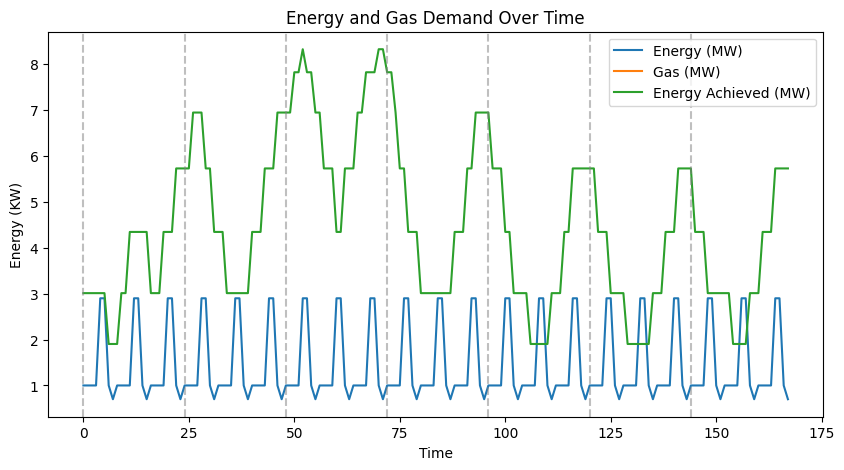

In [13]:
_, energy_achieved_hour = payback(-train_Y.max().item(), train_X[train_Y.argmax()].tolist())

plt.figure(figsize=(10, 5))
plt.plot(demand['Energy (KW)'], label='Energy (MW)')
plt.plot(demand['Gas (KW)'], label='Gas (MW)')
plt.plot(energy_achieved_hour, label='Energy Achieved (MW)')
for x in range(0, demand.shape[0], 24):
    plt.axvline(x=x, color='grey', linestyle='--', alpha=0.5)
plt.xlabel('Time')
plt.ylabel('Energy (KW)')
plt.title('Energy and Gas Demand Over Time')
plt.legend(loc='upper right')
plt.show()
